In [1]:
import numpy as np
from pathlib import Path
import pandas as pd
from tqdm.auto import tqdm
from scipy.stats import zscore


In [2]:
workdir = Path("/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/mouse_skull_workdir/")

In [66]:
scallings = []
index = []
for fold in tqdm(list(workdir.iterdir())):
    scaller_mat = np.loadtxt(fold/"result_affine.mat")
    # Perform SVD decomposition
    U, s, V = np.linalg.svd(scaller_mat)
    
    scallings.append( s )
    index.append(fold.name)



  0%|          | 0/767 [00:00<?, ?it/s]

array([[<AxesSubplot:title={'center':'0'}>,
        <AxesSubplot:title={'center':'1'}>],
       [<AxesSubplot:title={'center':'2'}>, <AxesSubplot:>]], dtype=object)

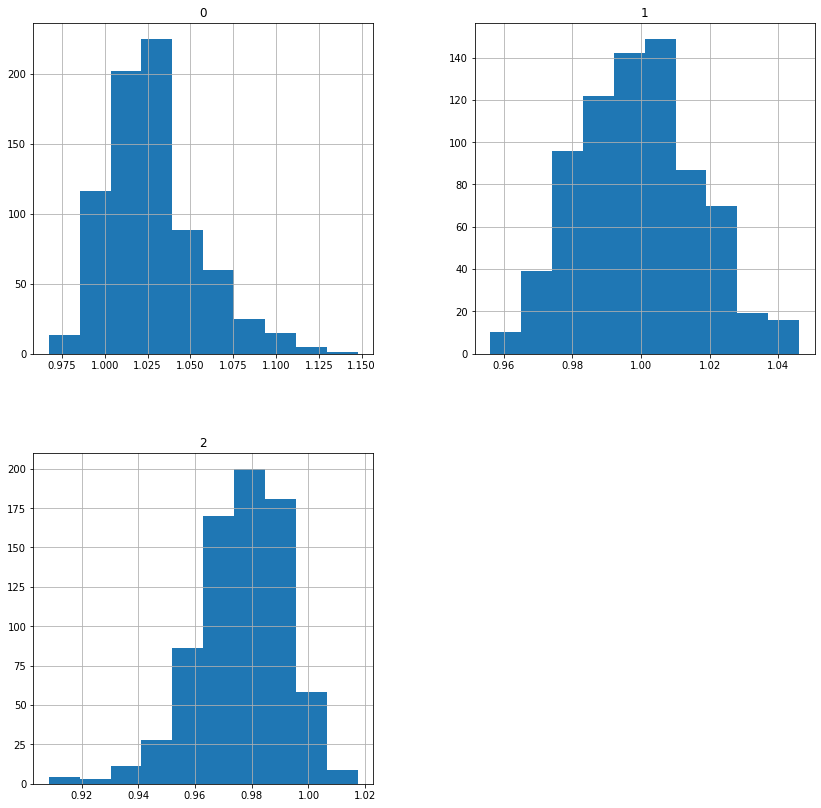

In [67]:
df_scal = pd.DataFrame(scallings,index=index)
### remove outliers 
threshold = 1.5
z_scores = df_scal.apply(zscore)
#z_scores = pd.DataFrame(df_scal.sum(axis=1)).apply(zscore)
abs_z_scores = np.abs(z_scores)
filtered_entries = (abs_z_scores > threshold).any(axis=1)
outliers = df_scal[filtered_entries]
df_scal = df_scal[~filtered_entries]
df_scal.hist(figsize=(14,14))


In [68]:
males = []
females = []
for fold in tqdm(df_scal.index):
    s = df_scal.loc[fold].values
    if "F" == fold.split("_")[1]:

        males.append( s  )
    elif "M" == fold.split("_")[1]:
        females.append( s  )
    else:
        print("ERRROR " + fold.name)

pd_males = pd.DataFrame(males)
pd_females = pd.DataFrame(females)


  0%|          | 0/750 [00:00<?, ?it/s]

<AxesSubplot:>

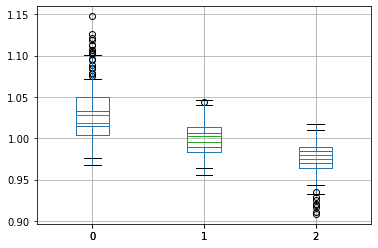

In [69]:
pd_males.boxplot()
pd_females.boxplot()

In [70]:
pd_males.describe()

,0,1,2
count,339.000000,339.000000,339.000000
mean,1.021277,0.995199,0.973248
std,0.023491,0.016318,0.016538
min,0.967291,0.956100,0.908462
25%,1.004049,0.983241,0.963525
50%,1.018853,0.995884,0.974975
75%,1.032394,1.006285,0.984741
max,1.121696,1.044471,1.010233


In [71]:
pd_females.describe()

,0,1,2
count,411.000000,411.000000,411.000000
mean,1.033711,1.002626,0.979558
std,0.028195,0.017105,0.014350
min,0.975857,0.964280,0.925503
25%,1.014533,0.989879,0.969734
50%,1.028681,1.002573,0.980353
75%,1.049443,1.014176,0.989333
max,1.147640,1.046102,1.017291


<AxesSubplot:>

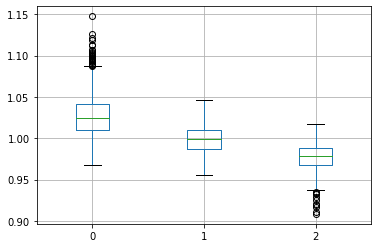

In [72]:
df_scal.boxplot()

In [73]:
df_scal.describe()

,0,1,2
count,750.000000,750.000000,750.000000
mean,1.028091,0.999269,0.976706
std,0.026880,0.017147,0.015685
min,0.967291,0.956100,0.908462
25%,1.009843,0.986754,0.967689
50%,1.024319,0.999098,0.977952
75%,1.040930,1.010584,0.987970
max,1.147640,1.046102,1.017291


In [74]:
df_scal[df_scal[0]>1.3]

,0,1,2


In [75]:
df_scal[df_scal[2]<0.8]

,0,1,2


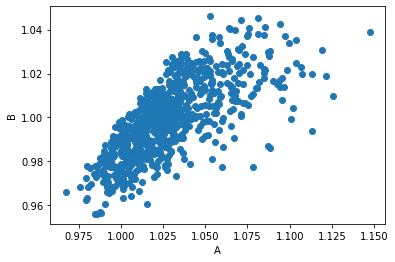

In [76]:
import matplotlib.pyplot as plt

plt.scatter(df_scal[0], df_scal[1])
plt.xlabel('A')
plt.ylabel('B')
plt.show()

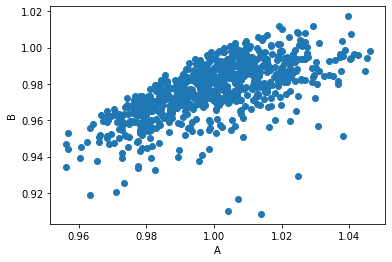

In [77]:
plt.scatter(df_scal[1], df_scal[2])
plt.xlabel('A')
plt.ylabel('B')
plt.show()

In [19]:
threshold = 2
z_scores = df_scal.apply(zscore)
abs_z_scores = np.abs(z_scores)
filtered_entries = (abs_z_scores > threshold).any(axis=1)
outliers = df_scal[filtered_entries]

In [20]:
outliers

,0,1,2
wt_M_82Z-CG992,1.346548,0.617886,0.527281
wt_M_82Z-10329,1.038456,0.950024,0.749481
wt_M_82Z-CE722,5.534689,1.694127,0.012933
wt_F_82Z-07342,5.759310,1.340288,0.023295
wt_F_83Z-CE969,1.135827,1.103073,0.699510


In [21]:
z_scores

,0,1,2
wt_M_82Z-10911,-0.040105,-0.001494,0.288151
wt_M_82Z-CF279,-0.141702,-0.204250,0.037559
wt_M_82Z-10328,0.125897,0.393485,0.183017
wt_F_82Z-06658,-0.228767,-1.201883,-0.692275
wt_F_82Z-08223,0.005001,-0.560191,-0.462658
...,...,...,...
wt_M_82Z-07734,-0.085222,0.079196,-0.138330
wt_M_82Z-06778,-0.169887,-0.258519,-0.036782
wt_F_82Z-09722,-0.026310,0.378860,0.351777
wt_M_82Z-CF991,-0.075653,0.410852,0.425800


In [80]:
pd_males.sum(axis=1).describe()

count    339.000000
mean       2.989724
std        0.047737
min        2.862461
25%        2.957505
50%        2.990670
75%        3.021715
max        3.135837
dtype: float64

In [81]:
pd_females.sum(axis=1).describe()

count    411.000000
mean       3.015895
std        0.050491
min        2.891294
25%        2.979852
50%        3.013201
75%        3.046251
max        3.185055
dtype: float64

<AxesSubplot:>

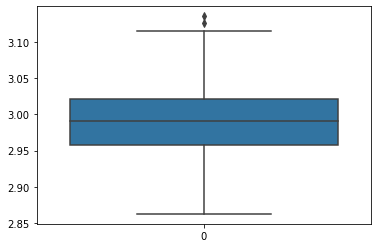

In [78]:
import seaborn as sns
sns.boxplot( data= pd_males.sum(axis=1))


<AxesSubplot:>

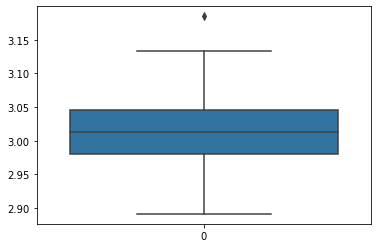

In [79]:
sns.boxplot( data= pd_females.sum(axis=1))

<AxesSubplot:>

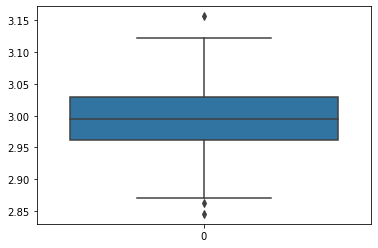

In [60]:
sns.boxplot( data= df_scal.sum(axis=1))

<AxesSubplot:ylabel='Count'>

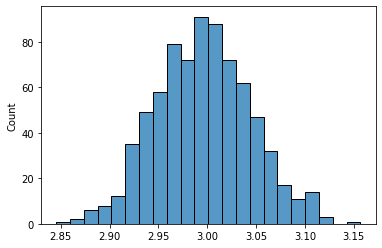

In [61]:
sns.histplot(df_scal.sum(axis=1))

<AxesSubplot:ylabel='Count'>

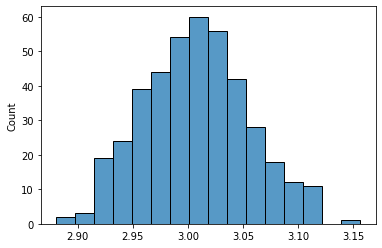

In [63]:
sns.histplot(pd_females.sum(axis=1)
             #,binrange=(2.5,3.4)
            )

<AxesSubplot:ylabel='Count'>

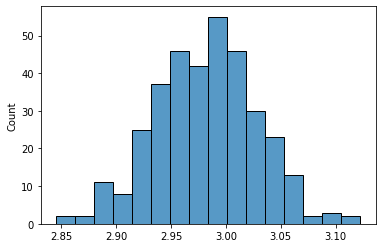

In [64]:
sns.histplot(pd_males.sum(axis=1))

<AxesSubplot:ylabel='Count'>

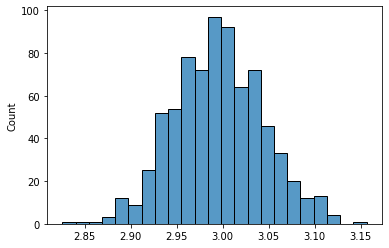

In [30]:
sns.histplot(df_scal[~filtered_entries].sum(axis=1))

In [27]:
threshold = 1.5
z_scores = df_scal.apply(zscore)
#z_scores = pd.DataFrame(df_scal.sum(axis=1)).apply(zscore)
abs_z_scores = np.abs(z_scores)
filtered_entries = (abs_z_scores > threshold).any(axis=1)
outliers = df_scal[filtered_entries]

In [28]:
outliers

,0,1,2
wt_M_82Z-10328,1.134733,0.920305,0.830305
wt_F_82Z-06658,1.219035,1.000616,0.897503
wt_F_82Z-07353,1.215512,0.931023,0.870882
wt_F_82Z-CF025,1.226717,0.880784,0.813809
wt_M_82Z-CF112,1.188505,0.916612,0.854615
...,...,...,...
wt_F_82Z-CF270,1.265121,0.940729,0.905659
wt_F_82Z-07609,1.176748,0.970448,0.913178
wt_M_82Z-11983,1.107932,0.990725,0.827026
wt_F_82Z-09722,1.177599,1.077316,0.830343


<AxesSubplot:>

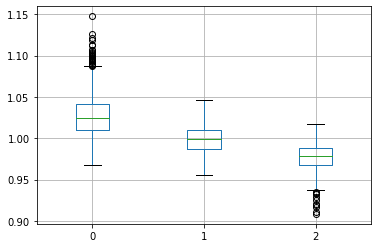

In [83]:
df_scal.boxplot()

In [30]:
list(df_scal[~filtered_entries].index)
import pathlib
res = pathlib.Path("/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/images_4_average.txt")

In [31]:
res.write_text('\n'.join(list(df_scal[~filtered_entries].index)))

9089

<AxesSubplot:>

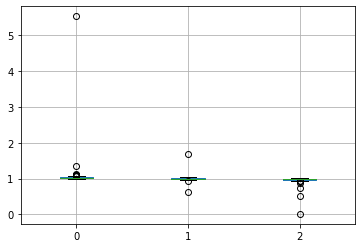

In [8]:
pd_females.boxplot()

In [84]:
pd_females.sum(axis=1).describe()

count    411.000000
mean       3.015895
std        0.050491
min        2.891294
25%        2.979852
50%        3.013201
75%        3.046251
max        3.185055
dtype: float64

In [85]:
pd_males.sum(axis=1).describe()

count    339.000000
mean       2.989724
std        0.047737
min        2.862461
25%        2.957505
50%        2.990670
75%        3.021715
max        3.135837
dtype: float64

In [82]:
df_scal[~filtered_entries].sum(axis=1).describe()

<ipython-input-82-1cd3e21dce14>:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_scal[~filtered_entries].sum(axis=1).describe()


count    750.000000
mean       3.004065
std        0.050929
min        2.862461
25%        2.968049
50%        3.003741
75%        3.037599
max        3.185055
dtype: float64

In [36]:
df_scal

,0,1,2
wt_M_82Z-10911,1.027605,0.998592,0.985607
wt_M_82Z-CF279,1.003495,0.991288,0.971808
wt_M_82Z-10328,1.066997,1.012822,0.979818
wt_F_82Z-06658,0.982834,0.955348,0.931620
wt_F_82Z-08223,1.038308,0.978465,0.944264
...,...,...,...
wt_M_82Z-07734,1.016898,1.001499,0.962123
wt_M_82Z-06778,0.996807,0.989333,0.967715
wt_F_82Z-09722,1.030878,1.012295,0.989111
wt_M_82Z-CF991,1.019169,1.013447,0.993187


In [39]:
df_scal.loc[df_scal.index[0]].values

array([1.02760458, 0.9985925 , 0.98560709])

In [89]:
(pd_females.sum(axis=1).describe()['mean'] - pd_males.sum(axis=1).describe()['mean'] ) / pd_females.sum(axis=1).describe()['mean']

0.008677533788343914

In [91]:
pd_females.sum(axis=1).describe()

count    411.000000
mean       3.015895
std        0.050491
min        2.891294
25%        2.979852
50%        3.013201
75%        3.046251
max        3.185055
dtype: float64

In [92]:
pd_males.sum(axis=1).describe()

count    339.000000
mean       2.989724
std        0.047737
min        2.862461
25%        2.957505
50%        2.990670
75%        3.021715
max        3.135837
dtype: float64